# Research behind Formation Review

Formation Review helps dance judges assess group formation accuracy. The experiments below test how reliably we can locate dancers on the stage and how those positions support alignment scores and the live stage-use heat map. The contact benchmarks measure the quality of the position estimates that feed the formation analysis.

The cells read saved results. The [master notebook](Master_Notebook.ipynb) walks through the judging tool, and the [300-image results](Experiment/lighting_expansion_300/RESULTS.md) give the training details.

In [1]:
from pathlib import Path
from collections import Counter
import json
from IPython.display import Image, Video, display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "tools/build_cvat_packs.py").exists()), None)
assert ROOT is not None, "Start Jupyter from the project folder."
EXP = ROOT / "Experiment/Dance_Overnight"
def read(name):
    return json.loads((EXP / name).read_text(encoding="utf-8"))


### 1. Try a point derived from the box

A box bottom is cheap. We also tried correcting it with box geometry alone.

In [2]:
g = read("geometry/results.json")["chosen"]["validation"]["selected"]
v = read("ending_experiment/results.json")["reference"]["old_development"]["selected"]
for name, r in [("Box geometry", g), ("Image-based support", v)]:
    print(f"{name}: {r['correct']}/{r['refs']} within 3%; hidden reported visible: {r['hidden_emitted']}")


Box geometry: 88/104 within 3%; hidden reported visible: 29
Image-based support: 99/104 within 3%; hidden reported visible: 4


The image-based model placed more points correctly and produced fewer false visible contacts. We kept the detector for boxes and trained a separate head for point and visibility.

### 2. Test smoothing on the same tracks

In [3]:
r = read("round2/previous_test_diagnostic.json")["continuity"]
for name, x in r.items():
    print(f"{name}: p99 acceleration {x['acceleration_p99']:.3f}; abrupt changes {x['abrupt_changes_over_half_pct']}")


baseline: p99 acceleration 0.875; abrupt changes 90
candidate: p99 acceleration 0.049; abrupt changes 0


The offline fit reduced abrupt changes on this diagnostic replay. It uses future frames and can blur fast motion.

### 3. Try more data and heavier alternatives

In [4]:
m = read("data/development_ending.json")
for split in ("train", "val"):
    frames = [(d, k) for d in m.values() for k in d[split]]
    crops = [o for d, k in frames for o in d["labels"][str(k)] if o["box"] is not None and o["contact"] != "uncertain"]
    print(split, len(frames), "frames;", len(crops), "usable crops")

d = read("detector_expanded/tracking_selection.json")
for name in ("baseline", "chosen"):
    v = d[name]["validation"]
    print(f"Detector {name}: {v['correct_initial_ids']}/{v['reference_boxes']} matched the initial ID")
t = read("temporal_experiment/results.json")["runs"]
for name, r in t.items():
    print(name, r["controlled_development"]["correct_by_tolerance_pct_width"]["3"], "/ 77")
s = read("seed_repeatability/results.json")["models"]
for name, r in s.items():
    print(name, r["controlled"]["correct_by_tolerance_pct_width"]["3"], "/ 77")


train 60 frames; 969 usable crops
val 11 frames; 180 usable crops
Detector baseline: 100/120 matched the initial ID
Detector chosen: 101/120 matched the initial ID
v8_repeated_current_s17 72 / 77
v8_temporal2_s17 72 / 77
v8_temporal5_s17 72 / 77
v6_attention_wide_s17 74 / 77
v9_repeat_wide_s29 73 / 77
v9_repeat_wide_s43 73 / 77
ensemble 74 / 77


Extra posture examples stayed. The detector change gave a small gain in this ID check. Neighboring frames and averaging three models did not beat the selected single-image head on this development comparison.

### 4. Freeze the pipeline and score fresh frames

Count every visible reference; a missing prediction is a miss. Distances are percentages of mat width.

In [5]:
r = read("final_confirmation/results.json")
for name, model in r["candidates"].items():
    refs = [x for x in model["records"] if x["contact"] == "visible"]
    correct = sum(x["error_pct"] is not None and x["error_pct"] <= 3 for x in refs)
    hidden = [x for x in model["records"] if x["contact"] == "hidden"]
    false_visible = sum(x["state"] == 1 for x in hidden)
    assert correct == model["all"]["correct_by_tolerance_pct_width"]["3"]
    print(f"{name}: {correct}/{len(refs)} within 3%; {false_visible}/{len(hidden)} hidden marked visible")


Incumbent support: 25/46 within 3%; 8/50 hidden marked visible
Expanded support: 29/46 within 3%; 5/50 hidden marked visible
Selected pipeline / box bottom: 19/46 within 3%; 5/50 hidden marked visible


Keep **YOLO → tracking → learned support and visibility → offline smoothing**. The improvement comes from seven frames in one choreography with draft reference labels. Dense overlaps still lose positions and identities.

In [6]:
display(Video(url="Experiment/Dance_Overnight/videos/final_confirmation_point_ablation.mp4", width=950))


### 5. Try filling a few more gaps

In [7]:
d = read("weak_contact/results.json")["previous_confirmation_diagnostic"]
for name, r in d.items():
    a = r["all"]
    print(name, a["correct_by_tolerance_pct_width"]["3"], "/ 46; hidden estimates:", a["hidden_estimated"])


original 29 / 46; hidden estimates: 2
weak_estimates 31 / 46; hidden estimates: 8


The replay adds a few correct positions and more guesses for hidden dancers. Keep these hollow estimates optional; this is a replay of inspected frames.

## 6. Select and revise 200 training frames for lighting variation

The original 60 training images stayed in the training set. We added 140 using farthest-point sampling across 14 time segments, with features for two luminance regions, saturation and crowd count. New samples were spaced by at least seven frames. The original 11 validation images and their surrounding ten-frame guard were excluded from new sampling. The reserved block and its buffer (3938–4092) were excluded from training.

The first proposals left many ambiguous contacts and missed visible body extents. We revised the source images with an explicit visual pass over boxes and supports, followed by a separate audit of ambiguous contacts. A dancer box covers visible body extent. The point marks the weight-bearing contact and can differ from the box bottom. Hidden, airborne and unresolved cases carry a status. The 12 floor guides per frame provide fixed-camera context, with an estimated rear boundary.

The CVAT transfer check compared every frame, ID, status, support kind, box, point and floor guide within 0.02 pixels. The positions are assistant estimates without independent human review.

In [8]:
from pathlib import Path
import json
from IPython.display import Image, Video, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "tools/run_notebooks.py").is_file())
TRIAL = ROOT / "Experiment/lighting_expansion_200"
REVISION = TRIAL / "visual_relabel"
RUN = TRIAL / "runs/lighting_200_visual_s17"
DEMO = RUN / "display_threshold_0.3"

def load(path):
    return json.loads(path.read_text(encoding="utf-8"))

def show_replay():
    display(Image(filename=str(DEMO / "replay_preview.jpg"), width=950))
    display(Video(url=(DEMO / "lighting_trial_replay.mp4").relative_to(ROOT).as_posix(), width=950))

200 training frames, 11 validation frames
{'visible': 3017, 'hidden': 618, 'uncertain': 4, 'airborne': 50}
CVAT transfer: passed across 3,689 boxes and 2,400 floor guides


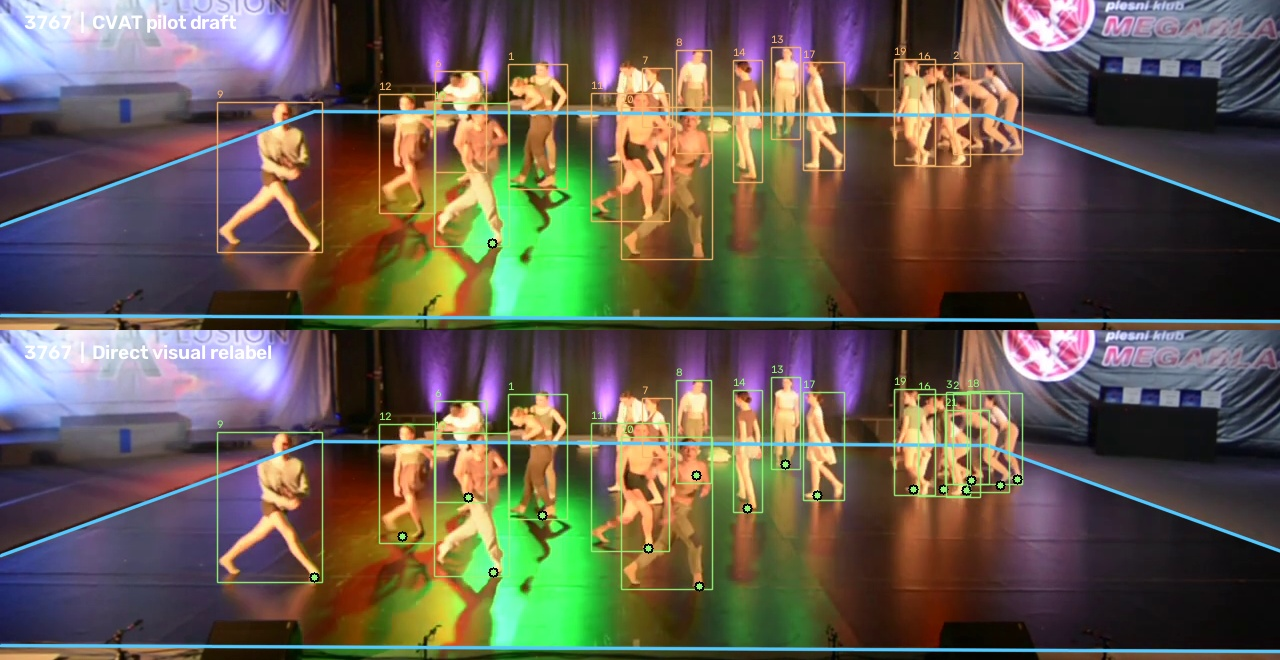

In [9]:
from collections import Counter
from xml.etree import ElementTree as ET

manifest = load(REVISION / "training_manifest.json")["lighting_200"]
train, val = set(manifest["train"]), set(manifest["val"])
image_ids = {int(path.stem.split("_")[-1]) for path in (TRIAL / "frames").glob("*.png")}
assert train == image_ids and len(train) == 200
assert len(val) == 11 and not train & (val | set(range(3938, 4093)))
counts = Counter(row["contact"] for frame in train for row in manifest["labels"][str(frame)])
audit = load(REVISION / "cvat_roundtrip_check.json")
xml = ET.parse(REVISION / "verified_cvat_export.xml")
assert len(xml.findall(".//image")) == audit["frames"] == 200
assert len(xml.findall(".//polyline")) == audit["floor_polylines"] == 2400
print(f"{len(train)} training frames, {len(val)} validation frames")
print(dict(counts))
print(f"CVAT transfer: {audit['status']} across {audit['dancer_boxes']:,} boxes and {audit['floor_polylines']:,} floor guides")
display(Image(filename=str(REVISION / "3767_before_after.jpg"), width=950))

## 7. Train the revised support model and select the checkpoint

The draft pilot and the visual revision used different labels. The draft pilot did not advance to confirmation. The revised run used a fresh ImageNet ResNet18 initialization, attention for support localization, brightness/crop/flip augmentation, posture-balanced sampling and seed 17. Of 3,689 labeled boxes, 3,685 were usable training crops. The run used the original 180 validation crops.

Epoch 1 minimized validation loss, while epoch 3 maximized validation joint F1 for the selected checkpoint. Joint F1 rewards visible predictions whose locations are correct. The final inference mode averages five crops and their flips. Its 0.90 reportability threshold was selected on the 11 validation images before confirmation scoring. Training loss fell while validation loss increased later in the run, which is consistent with overfitting.

BESTIJA | NVIDIA GeForce RTX 5080 | CUDA 12.8
30 epochs in 420.9 s; deployed epoch 3
Epoch  1: training loss 4.900, validation loss 5.944, joint F1 0.843
Epoch  3: training loss 4.018, validation loss 6.557, joint F1 0.879
Epoch 30: training loss 3.415, validation loss 7.644, joint F1 0.815
Inference mode crop5flip; calibrated threshold 0.90


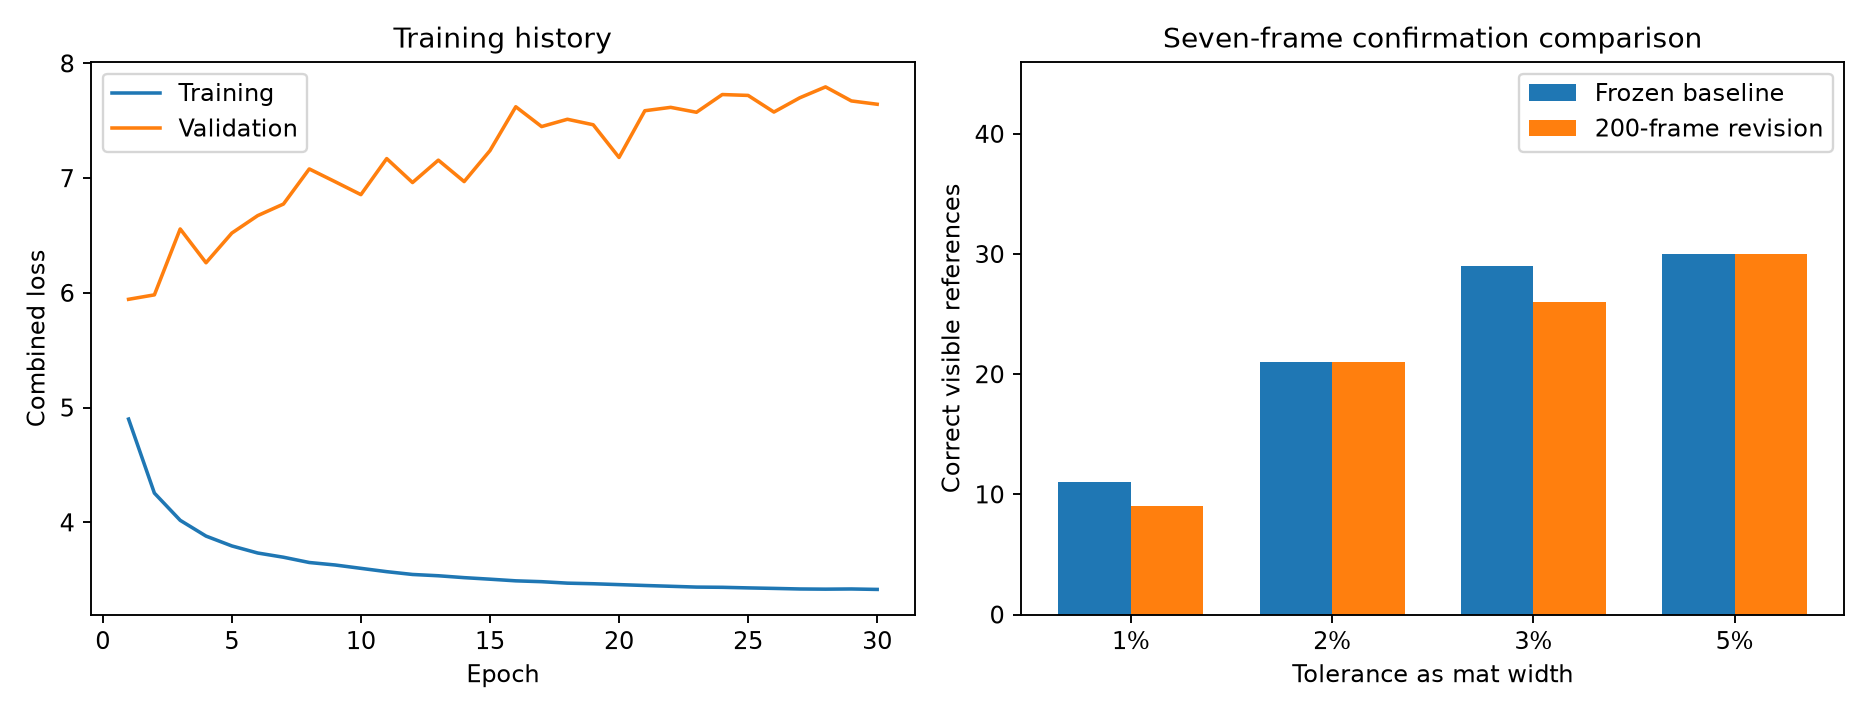

In [10]:
env = load(REVISION / "bestija_environment.json")
evidence = load(RUN / "selected_checkpoint_evidence.json")
history = load(RUN / "history.json")
selected = load(RUN / "evaluation/selection.json")
print(f"{env['hostname']} | {env['gpu']} | CUDA {env['cuda_runtime']}")
print(f"{len(history)} epochs in {evidence['completed']['seconds']:.1f} s; deployed epoch {evidence['deployed_epoch']}")
for row in [history[0], history[evidence["deployed_epoch"] - 1], history[-1]]:
    print(f"Epoch {row['epoch']:2}: training loss {row['train_loss']:.3f}, "
          f"validation loss {row['validation']['loss']:.3f}, joint F1 {row['validation']['selected']['joint_f1']:.3f}")
print(f"Inference mode {selected['mode']}; calibrated threshold {selected['threshold']:.2f}")
display(Image(filename=str(REVISION / "results_comparison.png"), width=950))

## 8. Score the frozen baseline and revised model

Both use the same cached detections, identities, calibration, full temporal extent, and offline fit. This comparison changes the support checkpoint and its validation-selected threshold. The seven reserved images are from this video. A missing prediction counts as a miss. The baseline leads at 1% and 3% tolerance, both tie at 2% and 5%, and the revision emits fewer false measured reports on hidden contacts.

In [11]:
from IPython.display import Markdown

comparison = load(RUN / "evaluation/results.json")
b, c = (comparison[name]["all"] for name in ("baseline", "candidate"))
lines = ["| Metric | Published baseline | 200-image revision |", "|---|---:|---:|"]
for tol in ("1", "2", "3", "5"):
    values = [f"{r['correct_by_tolerance_pct_width'][tol]}/{r['visible_references']}" for r in (b, c)]
    lines.append(f"| Visible contact within {tol}% of mat width | {values[0]} | {values[1]} |")
lines.append(f"| Hidden reported as measured | {b['hidden_measured']}/{b['hidden_references']} | "
             f"{c['hidden_measured']}/{c['hidden_references']} |")
display(Markdown("\n".join(lines)))

| Metric | Published baseline | 200-image revision |
|---|---:|---:|
| Visible contact within 1% of mat width | 11/46 | 9/46 |
| Visible contact within 2% of mat width | 21/46 | 21/46 |
| Visible contact within 3% of mat width | 29/46 | 26/46 |
| Visible contact within 5% of mat width | 30/46 | 30/46 |
| Hidden reported as measured | 5/50 | 3/50 |

## 9. Tune the map display threshold

Starting from the revision’s validation-selected 0.90 threshold, we tried 0.75, 0.60, 0.50, 0.40 and 0.30. Each variant admits a different set of raw support predictions, then refits the same trajectories. Dots count dancer positions per frame, including hollow estimates. Flicker counts dots that appear for one frame or vanish for one frame. The 99th percentile of step size and the change between successive steps measure motion on the map, in units of 1% of mat width. Smooth movement can still occur at a wrong location.

For the call, 0.30 adds 903 dots versus 0.40 while one-frame flicker and the motion statistics stay nearly identical. These are replay diagnostics for the 2,424-frame section, which includes training frames. The frozen accuracy table above uses 0.90.

| Threshold | Dots | Dots/frame | Single-frame flickers | Visibility toggles | Step p99 | Step change p99 |
|---:|---:|---:|---:|---:|---:|---:|
| 0.90 | 28,153 | 11.61 | 26 | 500 | 0.488 | 0.0434 |
| 0.75 | 30,997 | 12.79 | 20 | 479 | 0.514 | 0.0445 |
| 0.60 | 32,893 | 13.57 | 16 | 447 | 0.522 | 0.0460 |
| 0.50 | 33,990 | 14.02 | 13 | 416 | 0.510 | 0.0462 |
| 0.40 | 34,693 | 14.31 | 9 | 398 | 0.515 | 0.0464 |
| 0.30 | 35,596 | 14.68 | 9 | 378 | 0.516 | 0.0465 |

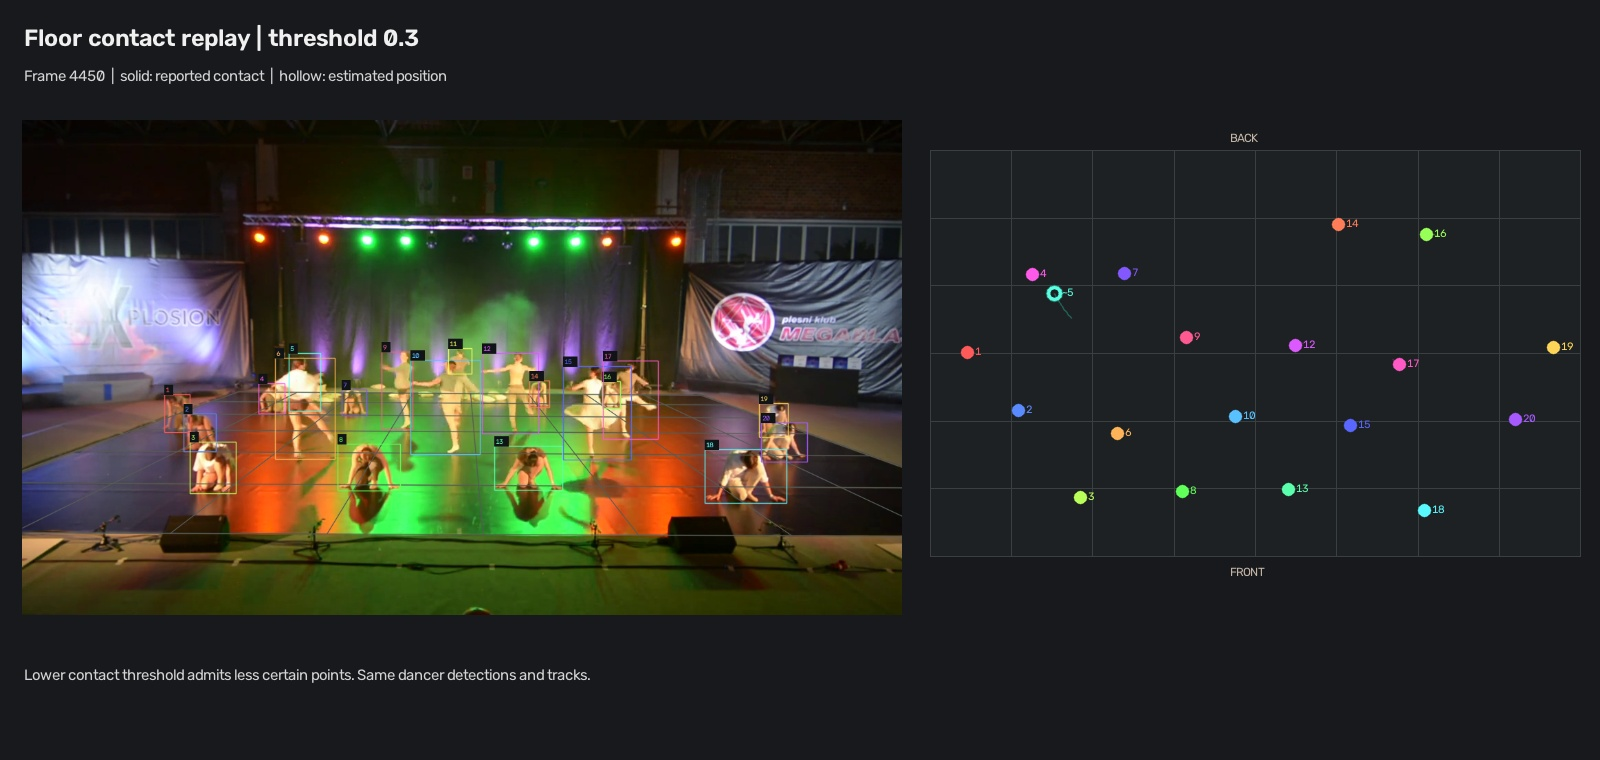

In [12]:
lines = ["| Threshold | Dots | Dots/frame | Single-frame flickers | Visibility toggles | Step p99 | Step change p99 |",
         "|---:|---:|---:|---:|---:|---:|---:|"]
for row in load(RUN / "display_sweep.json"):
    count = row["displayed_dots"]
    lines.append(f"| {row['threshold']:.2f} | {count:,} | {count / row['frames']:.2f} | "
                 f"{row['single_frame_flickers']} | {row['visibility_toggles']} | "
                 f"{row['step_p99']:.3f} | {row['acceleration_p99']:.4f} |")
display(Markdown("\n".join(lines)))
show_replay()

The reproducible sweep and map export are produced by [measure_display_sweep.py](Experiment/lighting_expansion_200/measure_display_sweep.py). The saved [0.30 coordinates](Experiment/lighting_expansion_200/runs/lighting_200_visual_s17/display_threshold_0.3/map_positions.json) are available for the formation work after the team discussion.

## 10. Evaluate boxes with standard AP

Compare COCO YOLO26m, the earlier dance detector and the 300-image fine-tune with the same tiles and image size. These are full-frame results after merging overlapping tiles. The training log reports validation on tiled images, which is a different protocol. Development has 197 reference boxes on 11 frames. The reserved diagnostic has 103 on seven frames. References are visually approximate and potentially incomplete. COCO detections also helped initialize some labels, which may favor the generic model.

In [13]:
from pathlib import Path
from csv import DictReader
import json
from IPython.display import Image, Markdown, Video, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'tools/run_notebooks.py').is_file())
exp = root / 'Experiment'
early = exp / 'Dance_Overnight'
trial = exp / 'lighting_expansion_300'
evidence = root / 'experiments'
run = trial / 'runs/lighting_300_visual_s17'

def load(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '|' + '|'.join(['---'] * len(headers)) + '|']
    lines += ['| ' + ' | '.join(map(str, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))

def show(path, width=930):
    display(Image(filename=str(path), width=width))

In [14]:
report = load(evidence / 'detector/comparison.json')
names = {'generic': 'COCO YOLO26m', 'published': 'Earlier dance detector', 'tuned_300': '300-image detector'}
def ap_row(key):
    dev = report['models'][key]['development']
    reserved = report['models'][key]['reserved_diagnostic']
    return [names[key], f"{dev['mAP50']:.3f}", f"{dev['mAP50_95']:.3f}",
            f"{reserved['mAP50']:.3f}", f"{reserved['mAP50_95']:.3f}"]
table(['Detector', 'Dev AP50', 'Dev AP50:95', 'Reserved AP50', 'Reserved AP50:95'],
      [ap_row(key) for key in names])

| Detector | Dev AP50 | Dev AP50:95 | Reserved AP50 | Reserved AP50:95 |
|---|---|---|---|---|
| COCO YOLO26m | 0.844 | 0.538 | 0.723 | 0.593 |
| Earlier dance detector | 0.799 | 0.465 | 0.753 | 0.413 |
| 300-image detector | 0.869 | 0.466 | 0.705 | 0.433 |

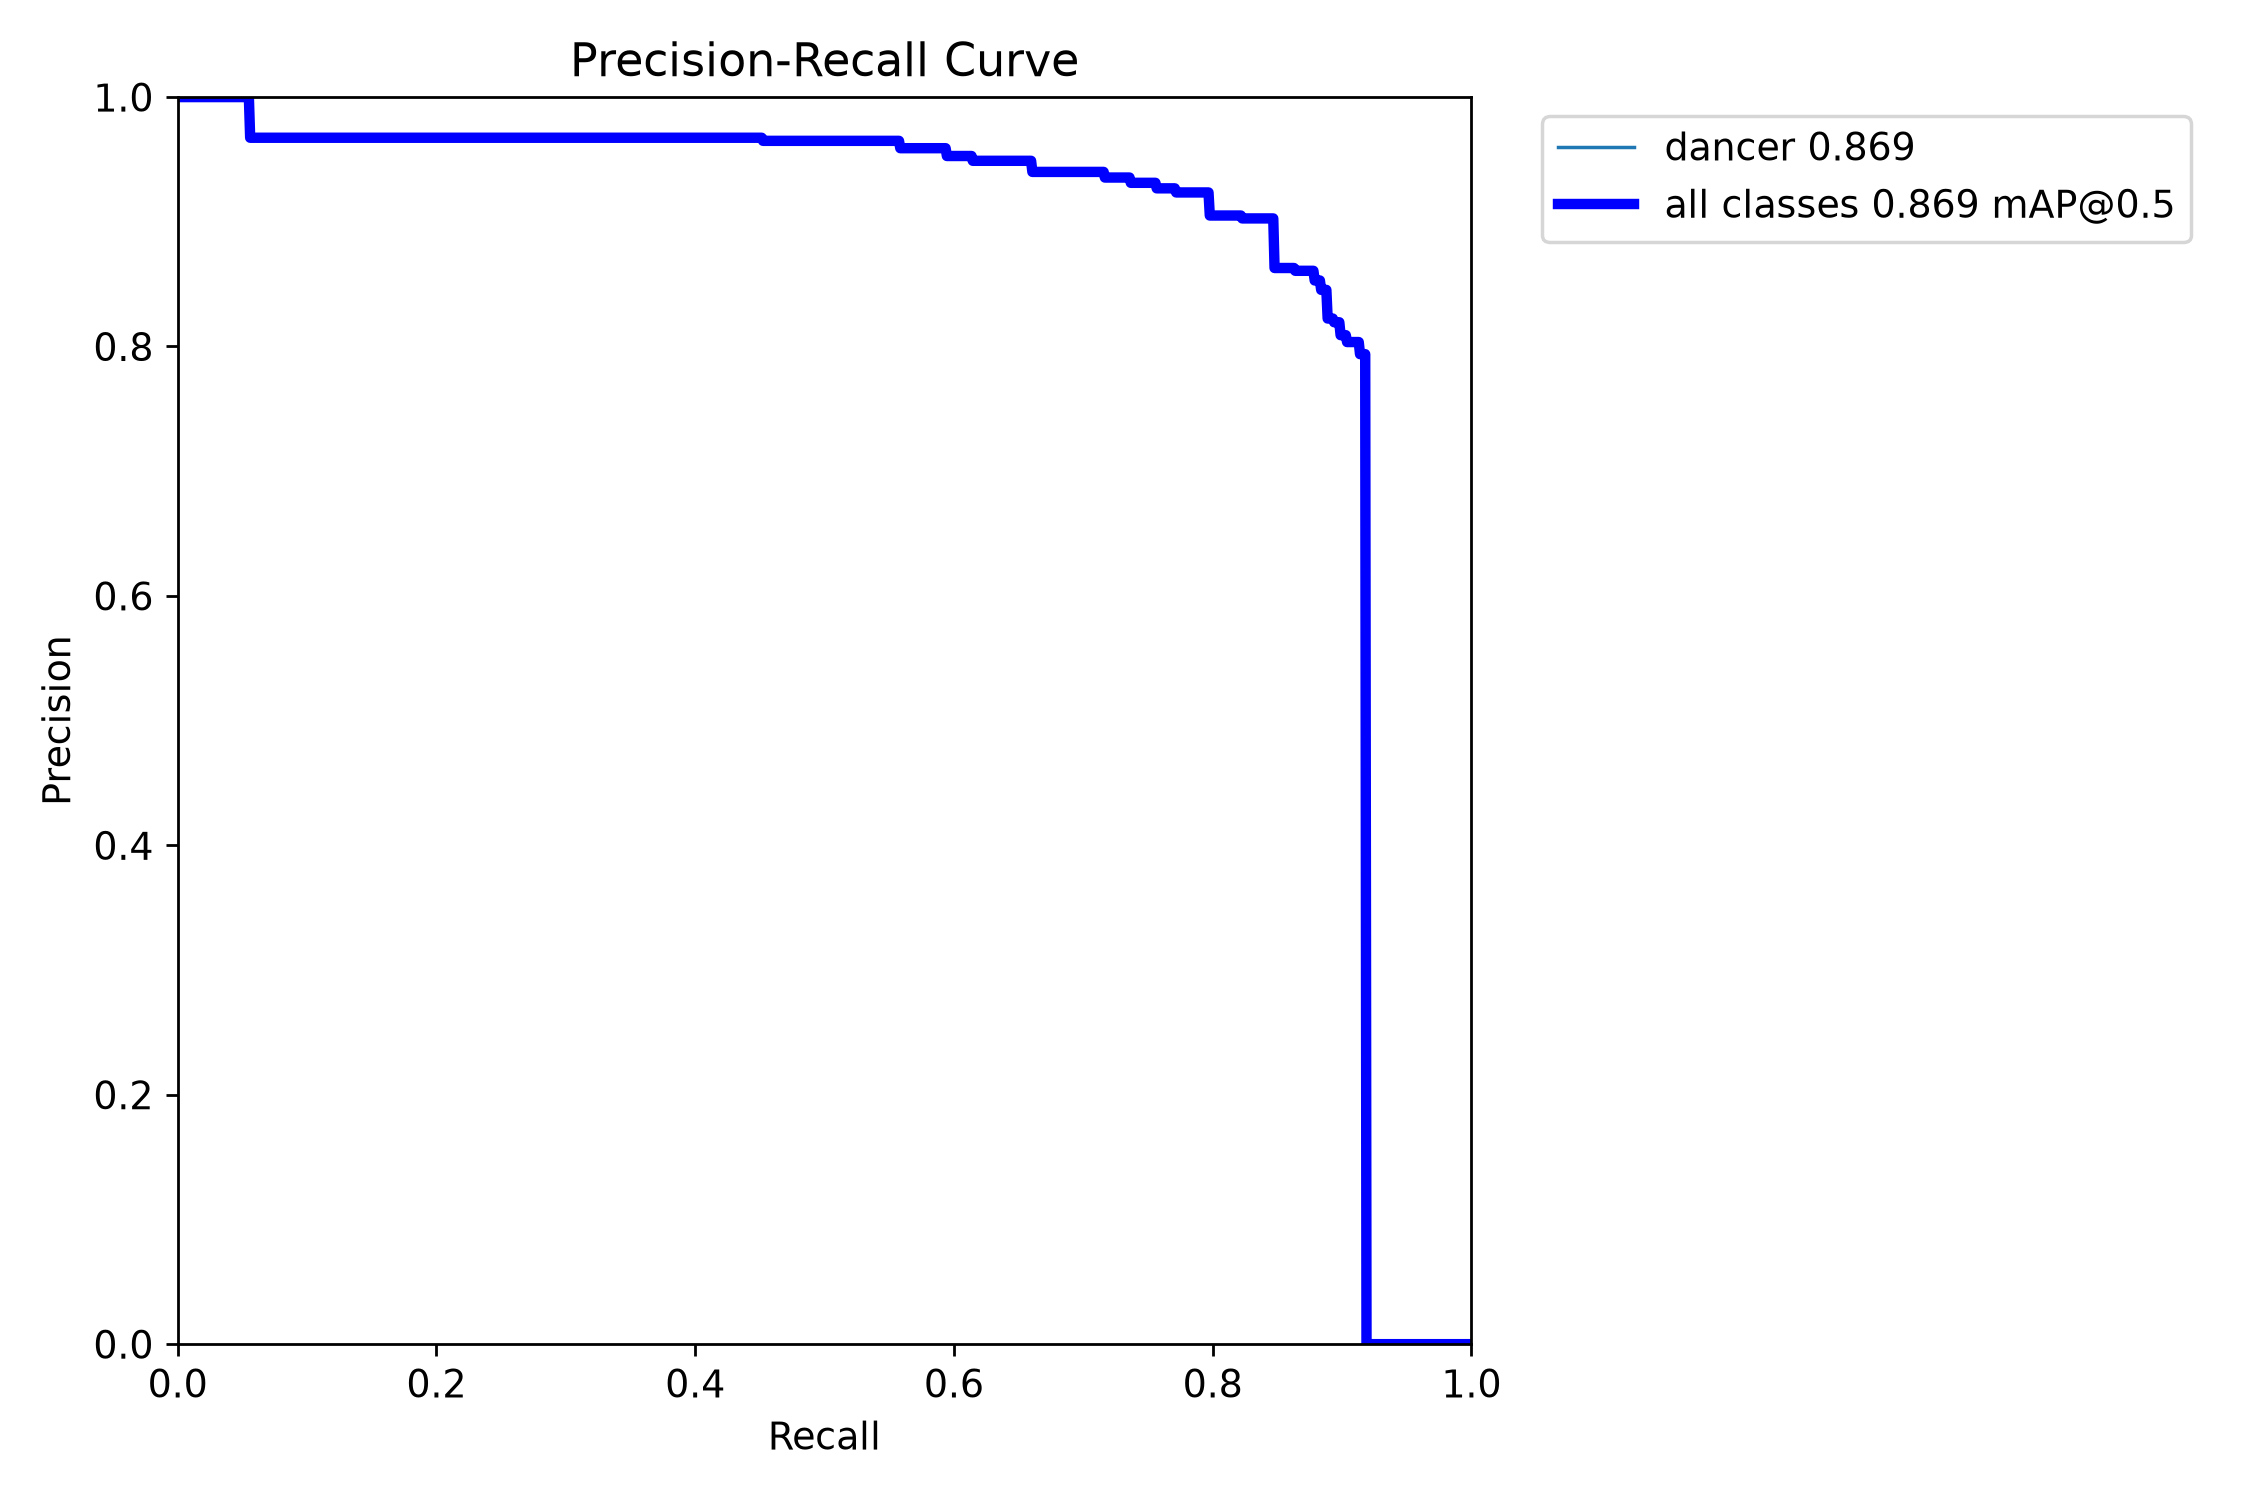

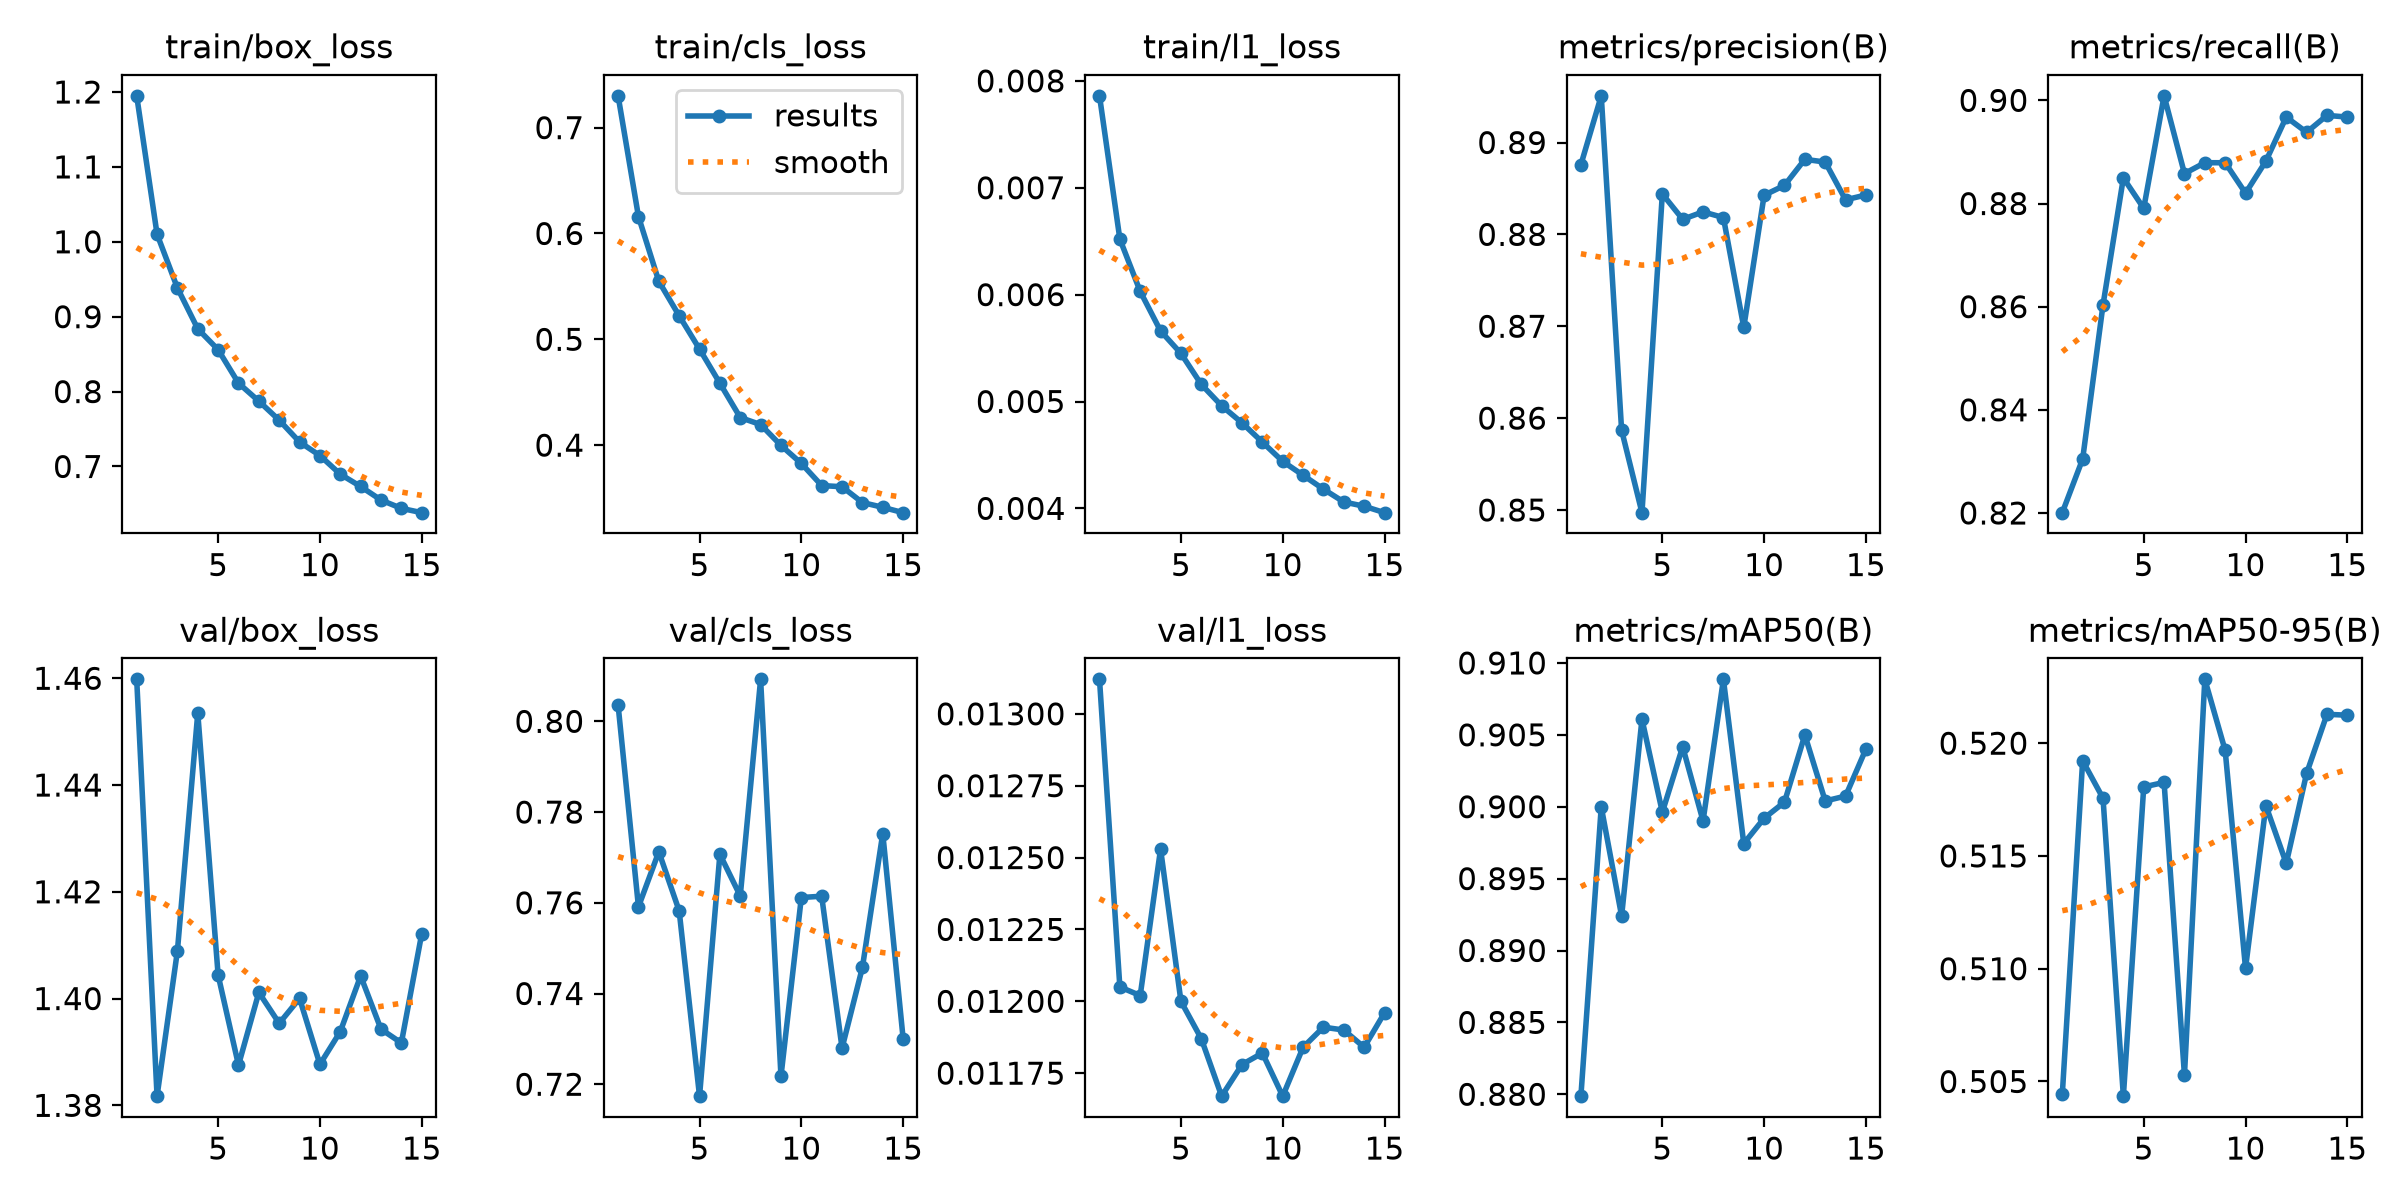

| Detector | Precision at 0.25 | Recall at 0.25 | Hidden-contact bodies matched |
|---|---|---|---|
| COCO YOLO26m | 0.844 | 0.766 | 36/68 |
| Earlier dance detector | 0.859 | 0.802 | 38/68 |
| 300-image detector | 0.852 | 0.878 | 51/68 |

| Detector | Precision at 0.25 | Recall at 0.25 | Hidden-contact bodies matched |
|---|---|---|---|
| COCO YOLO26m | 0.981 | 0.515 | 15/50 |
| Earlier dance detector | 0.669 | 0.806 | 34/50 |
| 300-image detector | 0.612 | 0.767 | 30/50 |

In [15]:
show(evidence / 'detector/tuned_300/development/BoxPR_curve.png', 640)
show(evidence / 'detector_training/results.png', 830)
for split_name in ('development', 'reserved_diagnostic'):
    table(['Detector', 'Precision at 0.25', 'Recall at 0.25', 'Hidden-contact bodies matched'],
          [[names[key], f"{report['models'][key][split_name]['precision_at_025_iou50']:.3f}",
            f"{report['models'][key][split_name]['recall_at_025_iou50']:.3f}",
            f"{h['matched_boxes']}/{h['reference_boxes']}"]
           for key in names for h in [report['models'][key][split_name]['by_contact_at_025_iou50']['hidden']]])

At confidence 0.25 the tuned detector matched more development bodies with hidden floor contact, from 38 to 51 out of 68. On the reserved diagnostic it fell from 34 to 30 out of 50, and generated more unmatched boxes. Frame 4021 shows the same issue around floor work and dense overlap. The [casebook](docs/error_casebook.md) records what changed, what did not improve, and which error needs independent adjudication.

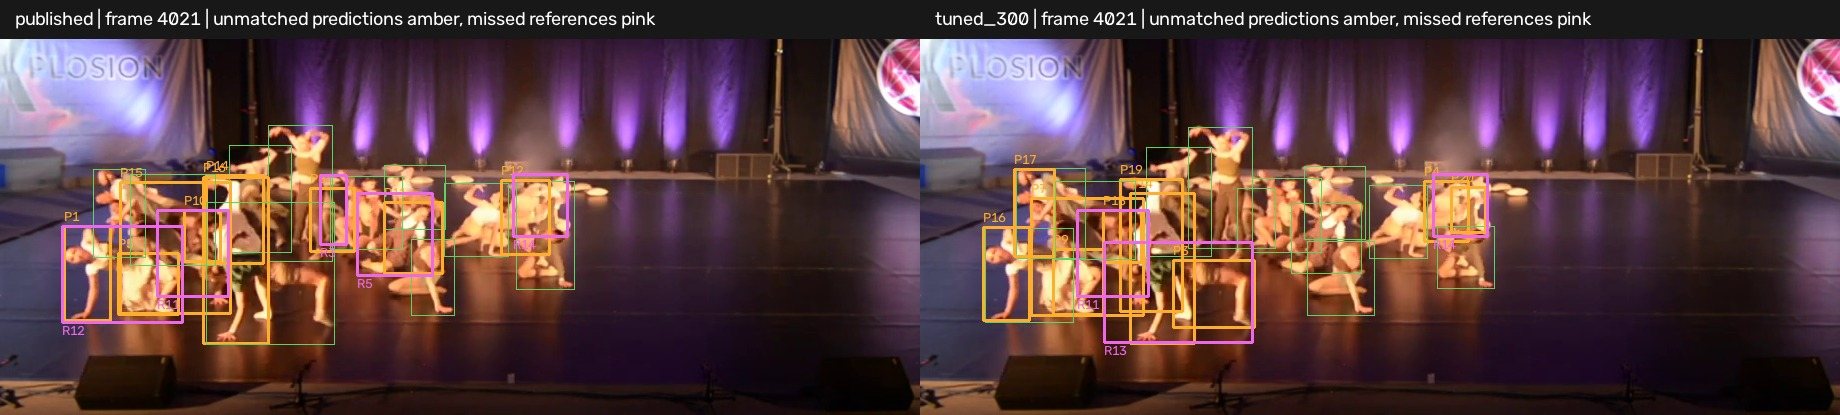

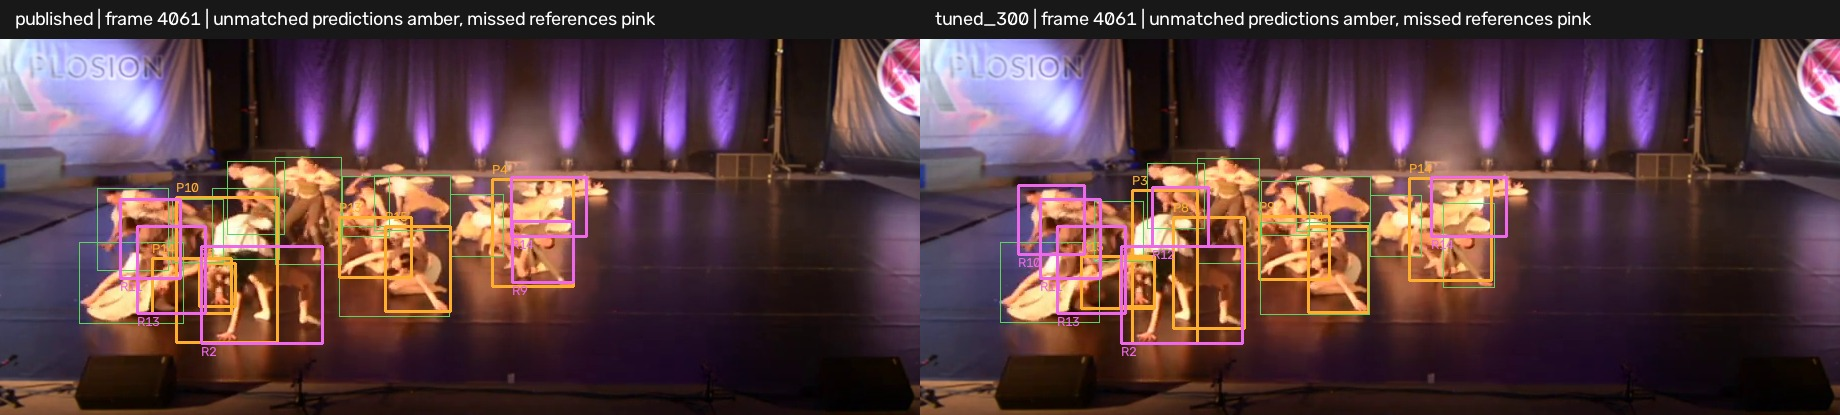

In [16]:
show(evidence / 'error_analysis/frame_4021.jpg')
show(evidence / 'error_analysis/frame_4061.jpg')

## 11. Audit the labels, repeats and modeling choices

The final split has a temporal guard and exact image checks. The stage-crop similarity check flags visually close frames without declaring them independent. The learning-curve evidence spans the 60-, 200- and 300-image runs, which also changed the labels and training recipe. Treat this as an incremental comparison. A controlled dataset-size curve, detector freeze/LR sweep and matched augmentation ablation are listed as open in the [experiment matrix](docs/experiment_log.md).

In [17]:
audit = load(evidence / 'data/split_audit.json')
for key, rows in audit['nearest_luma_signature'].items():
    closest = min(rows, key=lambda r: r['mean_absolute_luma_difference'])
    print(key, 'closest appearance pair:', closest)
repeat = load(early / 'label_repeatability/results.json')
print(f"Assistant repeat review: {repeat['same_contact_status']}/{repeat['samples']} states match; "
      f"median difference {repeat['median_pixel_difference']:.2f} px across {repeat['both_visible']} paired points.")

development closest appearance pair: {'source_frame': 5550, 'nearest_training_frame': 5561, 'mean_absolute_luma_difference': 0.307}
reserved closest appearance pair: {'source_frame': 4079, 'nearest_training_frame': 4096, 'mean_absolute_luma_difference': 11.225}
Assistant repeat review: 17/20 states match; median difference 6.32 px across 14 paired points.


In [18]:
joint = load(run / 'joint_evaluation/results.json')
support = load(run / 'evaluation/results.json')
models = [
    ('Published baseline', joint['published_baseline']['all']),
    ('200-image support revision', joint['revision_200']['all']),
    ('300 support with earlier detector', support['candidate_300_support']['all']),
    ('300 support and detector', joint['candidate_300_joint']['all']),
]
table(['Pipeline', 'Within 1%', 'Within 2%', 'Within 3%', 'Within 5%', 'Hidden reported'],
      [[name, *[f"{value['correct_by_tolerance_pct_width'][k]}/46" for k in ('1','2','3','5')],
        f"{value['hidden_measured']}/50"] for name, value in models])

| Pipeline | Within 1% | Within 2% | Within 3% | Within 5% | Hidden reported |
|---|---|---|---|---|---|
| Published baseline | 11/46 | 21/46 | 29/46 | 30/46 | 5/50 |
| 200-image support revision | 9/46 | 21/46 | 26/46 | 30/46 | 3/50 |
| 300 support with earlier detector | 13/46 | 21/46 | 28/46 | 31/46 | 3/50 |
| 300 support and detector | 14/46 | 22/46 | 27/46 | 33/46 | 2/50 |

## 12. Tracking, calibration and spatial analytics

The main demo uses the established identity and offline smoothing work. ByteTrack runs on new uploads because it starts from detected boxes without a manually seeded roster. BoT-SORT had fewer within-track gaps on the same 300-frame sample. The difference is about continuity; the identity diagnostic covers only four held-pose frames. A dedicated identity sequence and IDF1/HOTA remain open. Venue registration established usable camera alignment for the three later recordings. Training a landmark model remains a separate study.

The two occupancy maps use the same scale and a 0.6 m Gaussian bandwidth. Each covered frame contributes equal mass, with reflection at the boundary. Reported and estimated locations are plotted separately. Differences between the maps reveal where imputation changes the picture. Read the [extension evidence and limits](docs/rubric_and_gaps.md) before drawing conclusions about the choreography.

| Identity diagnostic | Matched boxes | Correct seed ID | Wrong seed ID |
|---|---|---|---|
| incumbent | 73 | 73 | 0 |
| expanded | 70 | 70 | 0 |

| Same detections, 300 frames | Track IDs | Median frames per ID | Within-ID gaps |
|---|---|---|---|
| ByteTrack | 50 | 55.5 | 123 |
| BoT-SORT | 49 | 58.0 | 100 |

| Same support inputs | Within 3% | P99 step change (% width) | Synthetic half-response lag |
|---|---|---|---|
| Raw | 29/46 | 7.522 | 0 frames |
| Causal Kalman | 33/46 | 1.686 | 1 frames |
| Offline robust | 29/46 | 0.048 | 0 frames |

proxy: coverage 2421/2424 frames
estimated: coverage 1913/2424 frames


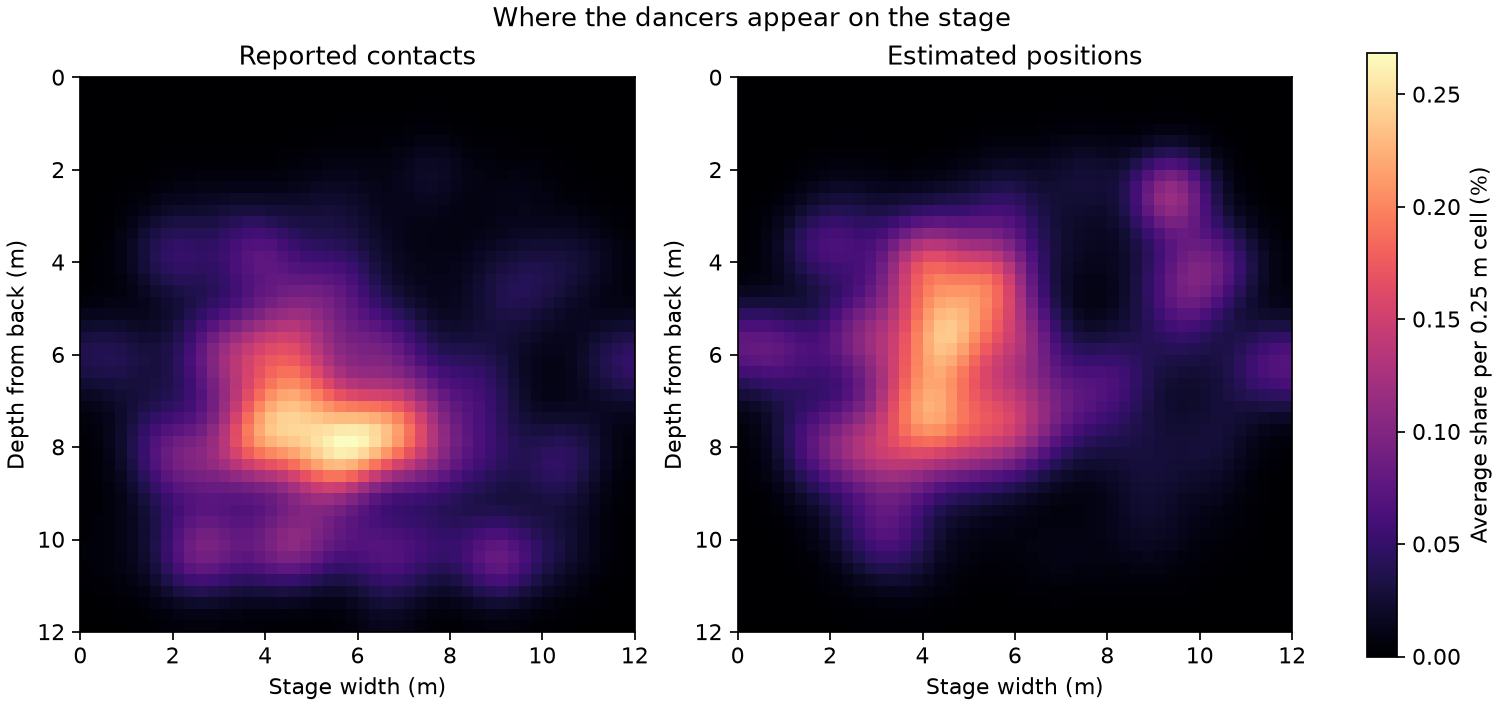

In [19]:
diagnostic = load(early / 'diagnostics/latest_identity_diagnostic.json')
table(['Identity diagnostic', 'Matched boxes', 'Correct seed ID', 'Wrong seed ID'],
      [[name, row['matched_observed_boxes'], row['matches_with_correct_initial_id'], row['wrong_initial_id_matches']]
       for name, row in diagnostic['candidates'].items()])
tracking = load(evidence / 'tracking/comparison.json')['results']
table(['Same detections, 300 frames', 'Track IDs', 'Median frames per ID', 'Within-ID gaps'],
      [[name, row['track_ids'], row['median_frames_per_id'], row['within_id_gaps']]
       for name, row in tracking.items()])
smoothing = load(evidence / 'tracking/smoothing.json')['results']
table(['Same support inputs', 'Within 3%', 'P99 step change (% width)', 'Synthetic half-response lag'],
      [[name, f"{row['within_3pct']}/{row['visible_refs']}",
        f"{row['continuity_on_common_samples']['acceleration_p99']:.3f}",
        f"{row['synthetic_3pct_step_half_response_frames']} frames"]
       for name, row in smoothing.items()])
analytics = load(evidence / 'analytics/summary.json')
for status, values in analytics['statistics'].items():
    print(f"{status}: coverage {values['covered_frames']}/{values['all_frames']} frames")
show(evidence / 'analytics/stage_occupancy.png')

The causal Kalman run localized 33/46 within 3% on the reused reserved images and reached half of the synthetic step one frame later. The offline fit localized 29/46 and produced the smoothest common samples. We kept the offline replay fit for visual review. The small diagnostic motivates an independent filter comparison before choosing a method for real-time feedback.